### **Imports**

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import display

if not (Path.cwd() / "src").is_dir() and (Path.cwd().parent / "src").is_dir():
    os.chdir(Path.cwd().parent)

%load_ext autoreload
%autoreload 2

from src.config import WORKING_DIR
from src.utils.visualization import (
    load_video_ablation_reports,
    plot_val_tracker_calibration,
    plot_video_ablation_dashboard,
)

### **Adaptive ROI & MOT Video Ablation Analysis (OpenVINO INT8)**

In [2]:
ABLATION_DIR = WORKING_DIR / "video_ablation"
REPORTS_DIR = ABLATION_DIR / "reports"
reports = load_video_ablation_reports(ABLATION_DIR, eval_split="test")
results_df = reports["results_df"]
metadata = reports["metadata"]
val_grid_df = reports["val_grid_df"]
val_roi_df = reports["val_roi_df"]
pd.set_option("display.max_columns", None)

### **Calibrated Val Hyperparameters & Environment Provenance**

In [6]:
provenance_df = pd.DataFrame([
    {"Item": "Eval Split", "Value": metadata.get("eval_split")},
    {"Item": "Sequences Evaluated", "Value": metadata.get("num_sequences")},
    {"Item": "Best ByteTrack Config (Val)", "Value": str((metadata.get("tracker_configs") or {}).get("bytetrack"))},
    {"Item": "Best OC-SORT Config (Val)", "Value": str((metadata.get("tracker_configs") or {}).get("ocsort"))},
    {"Item": "Calibrated max_lost_frames (Val)", "Value": metadata.get("max_lost_frames")},
    {"Item": "det_conf / seed_conf", "Value": f"{metadata.get('det_conf')} / {metadata.get('seed_conf')}"},
])
display(provenance_df.style.hide(axis="index"))

Item,Value
Eval Split,test
Sequences Evaluated,84
Best ByteTrack Config (Val),"{'match_thresh': 0.9, 'track_buffer': 15, 'track_thresh': 0.7}"
Best OC-SORT Config (Val),"{'det_thresh': 0.6, 'iou_threshold': 0.2, 'max_age': 15}"
Calibrated max_lost_frames (Val),3
det_conf / seed_conf,0.1 / 0.25


### **Validation Split: ByteTrack vs OC-SORT Calibration & ROI Hysteresis**

tracker,run_name,config_json,param_track_thresh,param_track_buffer,param_match_thresh,tracker_avg_latency_ms,tracker_avg_fps,HOTA,DetA,AssA,LocA,MOTA,MOTP,IDF1,CLR_Re,CLR_Pr,CLR_TP,CLR_FN,CLR_FP,IDSW,Frag,MT,PT,ML,param_det_thresh,param_max_age,param_iou_threshold
bytetrack,va_val_bytetrack_run_50,"{""match_thresh"": 0.9, ""track_buffer"": 15, ""track_thresh"": 0.7}",0.700,15.000,0.900,0.847,1180.086,76.560,75.581,78.000,86.669,89.824,84.632,91.287,92.893,97.100,7568.000,579.000,226.000,24.000,29.000,75.000,8.000,1.000,-,-,-
ocsort,va_val_ocsort_run_48,"{""det_thresh"": 0.6, ""iou_threshold"": 0.2, ""max_age"": 15}",-,-,-,0.595,1681.013,75.819,77.621,74.208,92.291,83.920,91.569,84.316,85.713,98.477,6983.000,1164.000,108.000,38.000,12.000,61.000,22.000,1.000,0.600,15.000,0.200


run_name,tracker,max_lost_frames,e2e_fps,e2e_mean_ms,e2e_p50_ms,e2e_p95_ms,pct_track_frames,search_transitions,HOTA,DetA,AssA,LocA,MOTA,MOTP,IDF1,CLR_Re,CLR_Pr,CLR_TP,CLR_FN,CLR_FP,IDSW,Frag,MT,PT,ML,track_recall_all,track_precision_all,track_recall_small,gt_small_count,tp_small_count,gt_total_count,tp_total_count,fp_total_count
va_val_roi_kalman_bytetrack_lost3,bytetrack,3,10.329,96.810,70.776,277.535,89.279,960,63.834,60.967,67.198,85.255,70.099,83.404,79.656,74.494,94.784,6069.000,2078.000,334.000,24.000,46.000,40.000,41.000,3.000,0.745,0.948,0.538,266,143,8147,6069,334
va_val_roi_kalman_bytetrack_lost4,bytetrack,4,11.671,85.680,65.338,235.161,89.930,879,63.424,60.325,67.046,85.292,69.179,83.476,79.174,73.610,94.665,5997.000,2150.000,338.000,23.000,49.000,39.000,39.000,6.000,0.736,0.947,0.534,266,142,8147,5997,338
va_val_roi_kalman_bytetrack_lost5,bytetrack,5,11.582,86.340,61.773,240.057,90.475,817,63.250,60.114,66.917,85.321,69.117,83.457,79.131,73.401,94.845,5980.000,2167.000,325.000,24.000,50.000,39.000,39.000,6.000,0.734,0.948,0.519,266,138,8147,5980,325
va_val_roi_kalman_ocsort_lost3,ocsort,3,8.493,117.746,72.764,342.362,84.333,1726,54.813,51.314,58.685,89.390,54.020,88.661,67.316,57.862,94.337,4714.000,3433.000,283.000,30.000,23.000,20.000,50.000,14.000,0.579,0.943,0.327,266,87,8147,4714,283
va_val_roi_kalman_ocsort_lost4,ocsort,4,8.840,113.124,78.612,339.963,85.327,1577,54.725,51.190,58.641,89.352,53.848,88.630,67.225,57.714,94.323,4702.000,3445.000,283.000,32.000,25.000,18.000,54.000,12.000,0.577,0.943,0.316,266,84,8147,4702,283
va_val_roi_kalman_ocsort_lost5,ocsort,5,14.444,69.231,48.993,207.870,86.061,1477,54.736,51.301,58.523,89.418,53.959,88.710,67.443,57.800,94.369,4709.000,3438.000,281.000,32.000,24.000,18.000,53.000,13.000,0.578,0.944,0.312,266,83,8147,4709,281


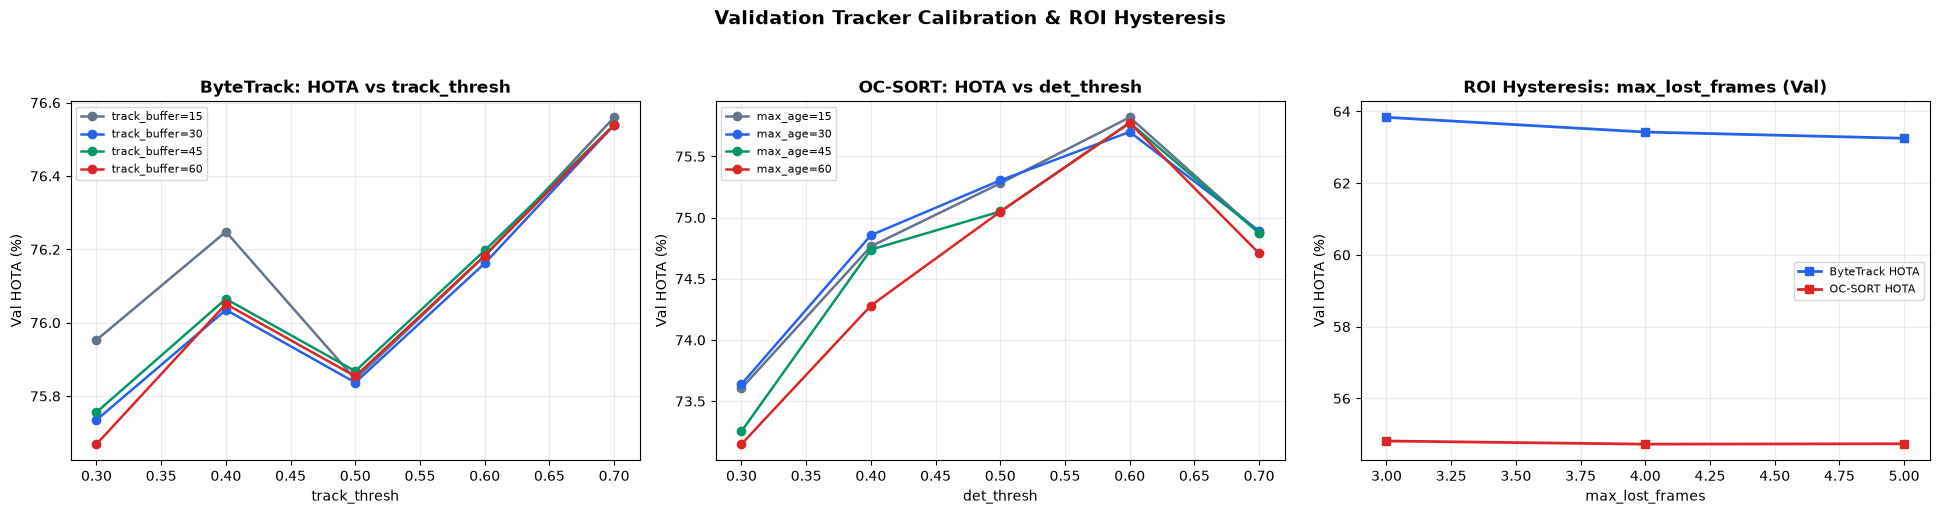

In [4]:
if not val_grid_df.empty:
    best_val_rows = (
        val_grid_df.sort_values(["HOTA", "IDF1"], ascending=[False, False])
        .groupby("tracker", as_index=False)
        .first()
    )
    display(best_val_rows.style.format(precision=3, na_rep="-").hide(axis="index"))

if not val_roi_df.empty:
    display(val_roi_df.style.format(precision=3, na_rep="-").hide(axis="index"))

if not val_grid_df.empty:
    plot_val_tracker_calibration(
        val_grid_df,
        val_roi_df=val_roi_df if not val_roi_df.empty else None,
        save_path=REPORTS_DIR / "val_tracker_calibration.png",
    )

### **Test Split: Full 1280 vs Resize 640 vs ROI Static vs ROI Kalman**

mode,tracker,e2e_fps,e2e_mean_ms,e2e_p95_ms,speedup_vs_full1280,pct_track_frames,search_transitions,HOTA,IDF1,MOTA,DetA,AssA,IDSW,Frag,track_recall_small (%)
full_1280,bytetrack,5.82,171.91,220.36,1.00,0.00,0,70.73,83.95,82.61,69.59,72.37,38.00,26.00,61.38
full_1280,ocsort,5.65,177.08,253.01,1.00,0.00,0,71.48,79.97,76.29,70.40,72.71,37.00,8.00,50.86
resize_640,bytetrack,11.62,86.04,139.15,2.00,100.00,0,49.37,63.55,48.03,40.90,59.96,18.00,17.00,6.92
resize_640,ocsort,23.15,43.19,54.16,4.10,100.00,0,43.15,51.66,38.03,35.60,52.37,25.00,4.00,4.61
roi_static,bytetrack,14.51,68.93,194.16,2.49,81.51,1207,60.37,76.45,64.88,55.62,65.88,21.00,40.00,45.97
roi_static,ocsort,11.64,85.89,227.66,2.06,77.17,1975,52.63,63.74,50.60,47.81,58.03,24.00,7.00,33.72
roi_kalman,bytetrack,9.26,107.94,320.27,1.59,81.49,1211,60.31,76.23,63.87,55.39,66.05,24.00,46.00,45.24
roi_kalman,ocsort,7.45,134.30,353.25,1.32,76.99,2002,50.76,61.93,50.51,47.24,54.62,24.00,9.00,30.98


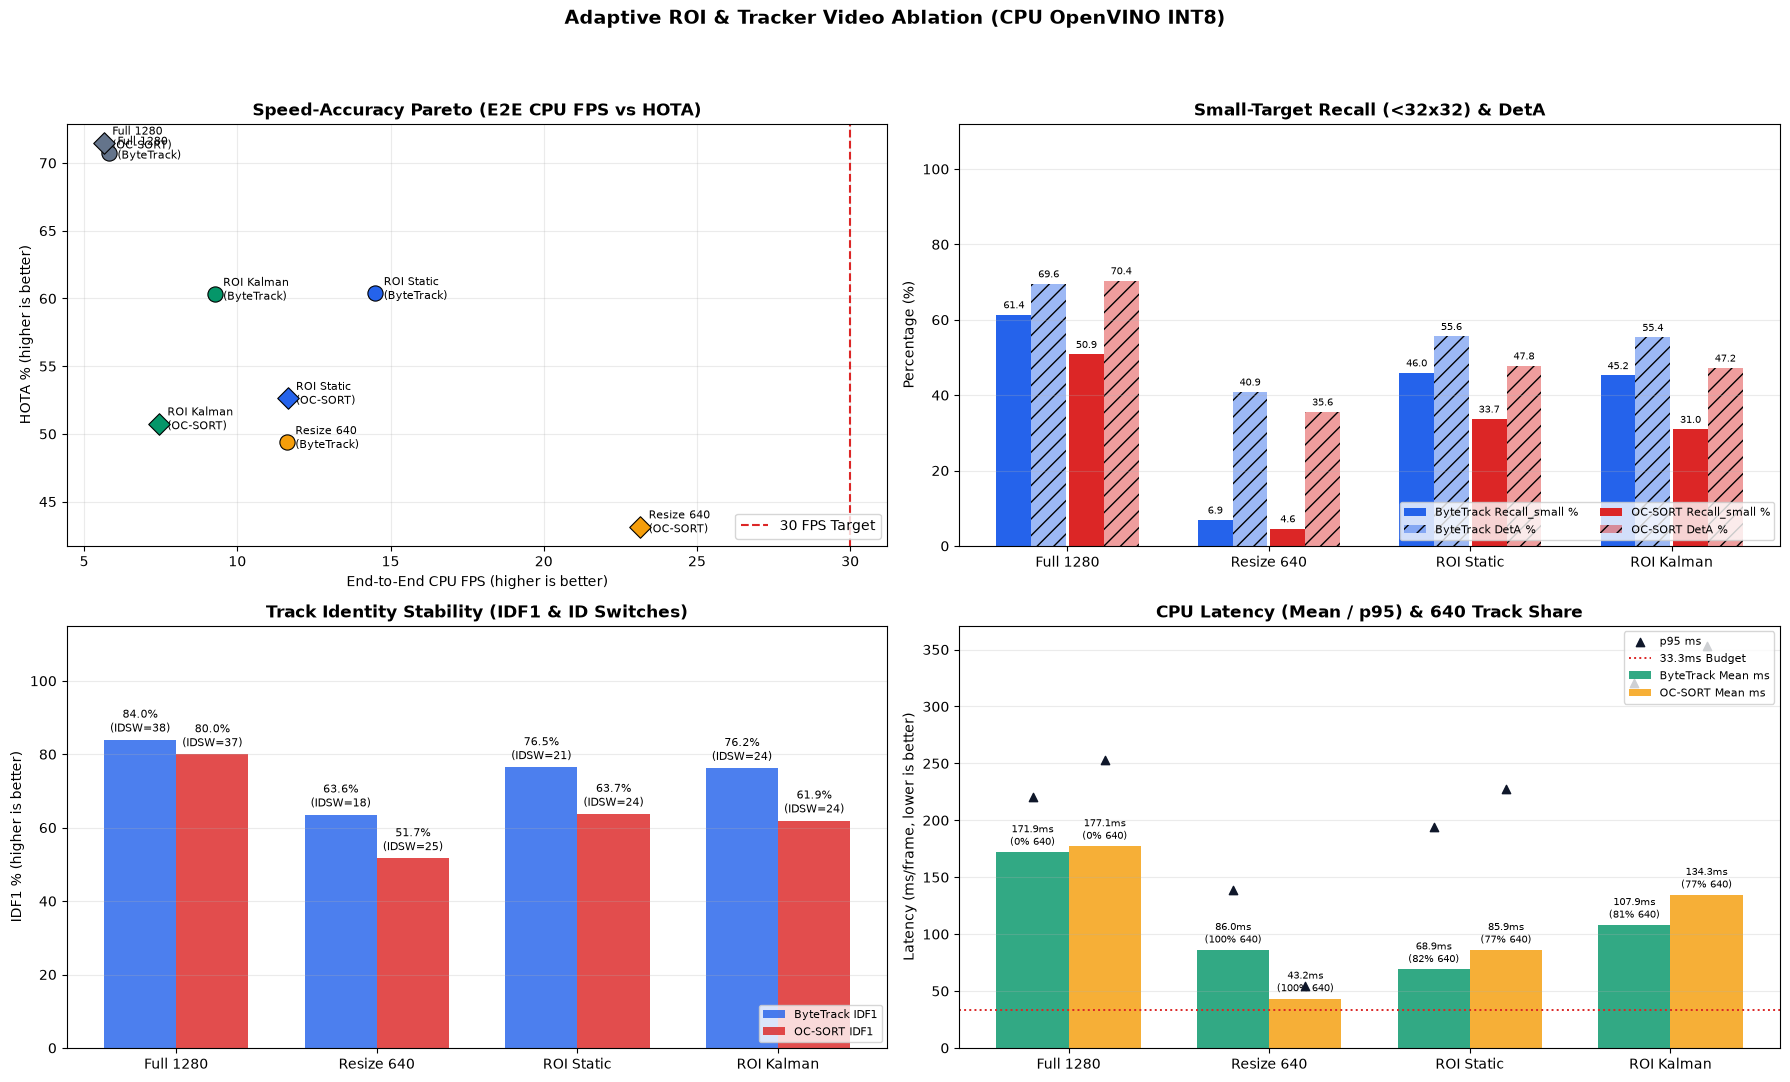

In [ ]:

view_df = results_df.copy()
full_baselines = view_df[view_df["mode"] == "full_1280"].set_index("tracker")["e2e_mean_ms"].to_dict()
view_df["speedup_vs_full1280"] = view_df.apply(
    lambda r: (full_baselines[r["tracker"]] / r["e2e_mean_ms"]) if r["tracker"] in full_baselines and r["e2e_mean_ms"] > 0 else float("nan"),
    axis=1,
)
view_df["track_recall_small (%)"] = view_df["track_recall_small"] * 100.0
display_cols = [
    "mode", "tracker", "e2e_fps", "e2e_mean_ms", "e2e_p95_ms", "speedup_vs_full1280",
    "pct_track_frames", "search_transitions", "HOTA", "IDF1", "MOTA", "DetA", "AssA",
    "IDSW", "Frag", "track_recall_small (%)",
]
display(view_df[[c for c in display_cols if c in view_df.columns]].style.format(precision=2, na_rep="-").hide(axis="index"))

plot_video_ablation_dashboard(
    results_df,
    target_fps=float(metadata.get("fps", 30)),
    save_path=REPORTS_DIR / "test_video_ablation_dashboard.png",
)

## **Adaptive ROI & MOT Video Ablation Conclusions (val → test, OpenVINO INT8)**

### 1. Calibrated Validation Hyperparameters (`val`, 84 sequences)
- **Tracker Grid Search (140 runs over cached `1280` OpenVINO INT8 detections):**
  - **`ByteTrack` (Best):** `track_thresh=0.7`, `track_buffer=15`, `match_thresh=0.9` → `HOTA=76.560`, `IDF1=91.287`, `MOTA=89.824`, `IDSW=24` (`0.85 ms/frame` tracker overhead).
  - **`OC-SORT` (Best):** `det_thresh=0.6`, `max_age=15`, `iou_threshold=0.2` → `HOTA=75.819`, `IDF1=84.316`, `MOTA=83.920`, `IDSW=38` (`0.59 ms/frame`).
- **ROI Hysteresis Calibration (`max_lost_frames` ∈ {3, 4, 5}):** **`max_lost_frames=3`** achieved the highest mean validation `HOTA` across trackers (`ByteTrack`: `HOTA=63.834`, `Small Recall=53.76%` [143/266], `89.28%` `640`-crop share; `OC-SORT`: `HOTA=54.813`, `Small Recall=32.71%`).

### 2. Frozen `test` Split Summary (`84` sequences, `9,437` frames, `694` small GT targets)

| Mode | Tracker | `e2e_fps` (`mean / p50 ms`) | `% Track 640` | `HOTA` | `IDF1` | `MOTA` | `IDSW` | `Small Recall` (`tp/694`) |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| `full_1280` | `bytetrack` | `5.82` (`171.9 / 162.6`) | `0.0%` | `70.734` | `83.950` | `82.608` | `38` | **`61.38%`** (`426`) |
| `full_1280` | `ocsort` | `5.65` (`177.1 / 165.8`) | `0.0%` | **`71.477`** | `79.970` | `76.286` | `37` | `50.86%` (`353`) |
| `resize_640` | `bytetrack` | `11.62` (`86.0 / 78.7`) | `100.0%` | `49.374` | `63.553` | `48.032` | **`18`** | **`6.92%`** (`48`) |
| `resize_640` | `ocsort` | `23.15` (`43.2 / 41.4`) | `100.0%` | `43.151` | `51.658` | `38.028` | `25` | **`4.61%`** (`32`) |
| **`roi_static`** | **`bytetrack`** | **`14.51` (`68.9 / 43.3`)** | **`81.5%`** | **`60.370`** | **`76.452`** | **`64.875`** | `21` | **`45.97%`** (`319`) |
| `roi_static` | `ocsort` | `11.64` (`85.9 / 53.0`) | `77.2%` | `52.634` | `63.741` | `50.605` | `24` | `33.72%` (`234`) |
| `roi_kalman` | `bytetrack` | `9.26` (`107.9 / 69.5`) | `81.5%` | `60.315` | `76.232` | `63.874` | `24` | `45.24%` (`314`) |
| `roi_kalman` | `ocsort` | `7.45` (`134.3 / 79.0`) | `77.0%` | `50.755` | `61.928` | `50.506` | `24` | `30.98%` (`215`) |

### 3. Core Architectural Takeaways
1. **Why Adaptive ROI Solves the `resize_640` Small-Target Collapse:** Global downscaling (`resize_640`) destroys distant sub-`32×32 px` UAVs (`Small Recall` drops from `61.38%` in `full_1280` to **`6.92%`** with `ByteTrack` and **`4.61%`** with `OC-SORT`), pulling `HOTA` down by `-21.4` to `-28.3` points. Switching to `SEARCH 1280 ↔ TRACK 640` unscaled ROI cropping (`roi_static ByteTrack`) routes **`81.51%`** of frames through `640×640` inference, lifts `Small Recall` by **~6.6×** (`45.97%` vs `6.92%`), recovers `+11.0 HOTA` (`60.370`) and `+12.9 IDF1` (`76.452`), and speeds up e2e runtime vs `full_1280` (`14.51 FPS` vs `5.82 FPS`, `p50 = 43.3 ms`). *(The remaining gap to `full_1280` `HOTA 70.73` comes from single-ROI lock skipping off-crop secondary targets and up to `max_lost_frames=3` missed frames before `SEARCH 1280` re-acquisition.)*
2. **Why `ByteTrack` Outperforms `OC-SORT` in Adaptive ROI:** Across both ROI modes, `ByteTrack` beats `OC-SORT` by `+7.7..+9.6 HOTA`, `+12.7..+14.3 IDF1`, and `+12.3..+14.3 pp` `Small Recall`, while triggering **~39% fewer** `SEARCH ↔ TRACK` resets (`1,207–1,211` vs `1,975–2,002` transitions). Two-stage association rescues low-confidence detections down to `det_conf=0.10` when motion blur or partial occlusion depresses confidence, preventing premature ROI loss.
3. **`roi_static` vs `roi_kalman` Quality Equivalence:** Both ROI modes produce nearly identical accuracy (`HOTA 60.370` vs `60.315`, `IDF1 76.452` vs `76.232`, `track_frames = 7,692` vs `7,690` out of `9,437`). Because a `640×640` crop covers `±320 px` around the target center, normal inter-frame displacement stays inside static bounds, whereas irregular frame gaps in temporally deduplicated sequences limit linear-velocity extrapolation gains.

### 4. Benchmark Latency & CPU Thermal Throttling Evidence
Observed `e2e_fps` differences between configurations with **identical neural network compute** demonstrate that desktop CPU thermal throttling and OS background contention distorted late-run latency measurements during this multi-hour sweep:
- **Sustained Single-Process Load (~5h 34m continuous runtime):** The full `scripts/07_video_ablation.py --stage all` pipeline ran uninterrupted from `22:02:31` to `03:36:31` (`val` until `00:46:23`, followed immediately by all 8 sequential `9,437`-frame `test` passes until `03:36:31`).
- **Control Pair 1 (`resize_640` `ByteTrack` vs `OC-SORT` — Identical `100%` `640` Workload):** Both runs execute the exact same `640` OpenVINO INT8 detector across the exact same `9,437` frames (`search_frames=0`, `track_frames=9,437`), with `<1 ms/frame` tracker logic (`0.64 ms` vs `0.61 ms` on `val`). Yet `resize_640 ByteTrack` recorded **`86.04 ms/frame` (`11.62 FPS`, `p50=78.70 ms`)** while the immediately following `resize_640 OC-SORT` recorded **`43.19 ms/frame` (`23.15 FPS`, `p50=41.43 ms`)**—a **2.00×** wall-clock shift unrelated to algorithm complexity.
- **Control Pair 2 (`roi_static` vs `roi_kalman` `ByteTrack` — Identical `81.5%` `640` Split):** Both executed virtually the same number of heavy `1280` frames (`1,745` vs `1,747`) and fast `640` crops (`7,692` vs `7,690`). The Kalman update in `ROICenterForecaster` is a lightweight `4×4` matrix step (`<0.05 ms/frame`). Nevertheless, `roi_static ByteTrack` finished at **`68.93 ms` (`14.51 FPS`, `p50=43.27 ms`)** whereas `roi_kalman ByteTrack` (run 7th near the end of the 5.5-hour window) degraded to **`107.94 ms` (`9.26 FPS`, `p50=69.47 ms`, `p95=320.27 ms`)**. A matching swing appeared in `val` ROI calibration (`va_val_roi_kalman_ocsort_lost3/4`: `117.7 / 113.1 ms` vs `lost5`: `69.2 ms`).
- **Deployment Decision (`app.py` / HF Space):** Algorithmically, `roi_static` and `roi_kalman` have the same compute cost (`~81.5%` `640` crops). Because **`roi_static` + `ByteTrack`** achieved marginally better tracking accuracy and stability (`HOTA 60.370`, `IDF1 76.452`, `IDSW=21`) with lower `max_lost_frames=3` hysteresis, **`roi_static` + `ByteTrack`** is set as the default demo preset while keeping **`roi_kalman`** selectable in the UI for direct side-by-side comparison on user videos.